In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

In [2]:
df = pd.read_csv(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nInformation:")
df.info()

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   Onlin

In [4]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [6]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [7]:
df = df.drop(
    "customerID",
    axis=1
)

In [8]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [9]:
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

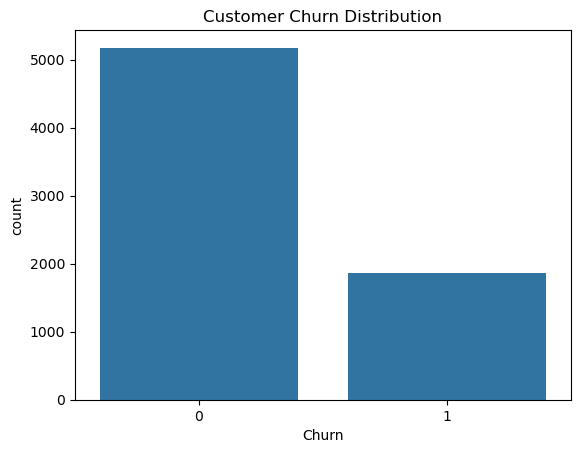

In [10]:
sns.countplot(
    x="Churn",
    data=df
)

plt.title("Customer Churn Distribution")
plt.show()

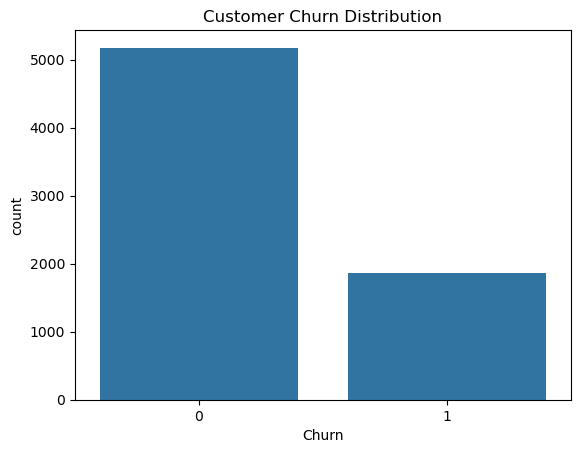

In [11]:
sns.countplot(
    x="Churn",
    data=df
)

plt.title("Customer Churn Distribution")
plt.show()

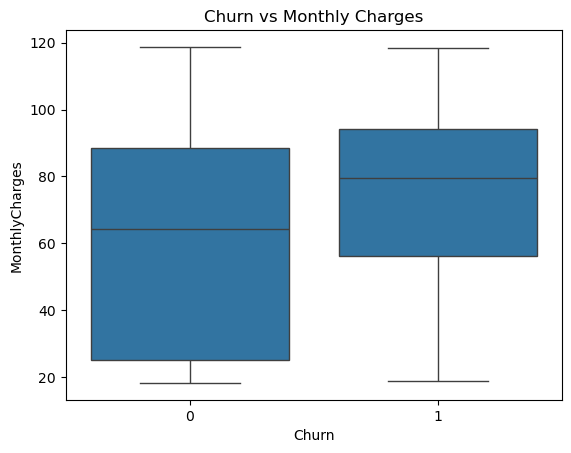

In [12]:
sns.boxplot(
    x="Churn",
    y="MonthlyCharges",
    data=df
)

plt.title("Churn vs Monthly Charges")
plt.show()

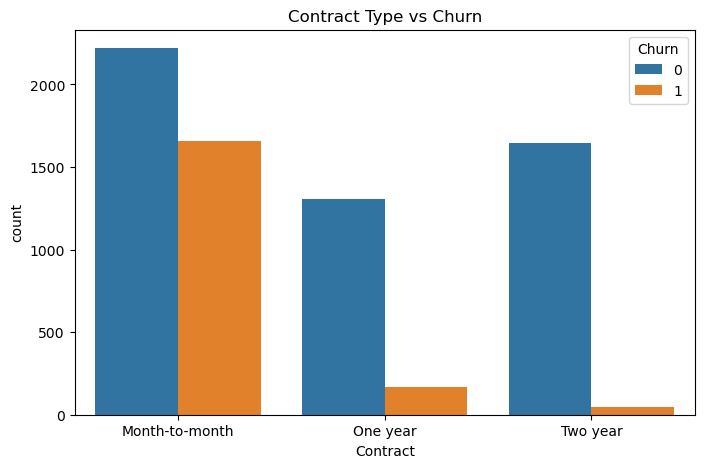

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x="Contract",
    hue="Churn",
    data=df
)

plt.title("Contract Type vs Churn")
plt.show()

In [14]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-1 Year",
        "1-2 Years",
        "2-4 Years",
        "4+ Years"
    ]
)

In [15]:
X = df.drop(
    "Churn",
    axis=1
)

y = df["Churn"]

In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [18]:
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [19]:
print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Testing:", X_test.shape)

Training: (4930, 20)
Validation: (1056, 20)
Testing: (1057, 20)


In [20]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

Numerical:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [21]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [22]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [25]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [23]:
def evaluate_model(model, X_data, y_data):

    predictions = model.predict(X_data)

    probabilities = model.predict_proba(
        X_data
    )[:, 1]

    results = {
        "Accuracy": accuracy_score(
            y_data,
            predictions
        ),

        "Precision": precision_score(
            y_data,
            predictions
        ),

        "Recall": recall_score(
            y_data,
            predictions
        ),

        "F1": f1_score(
            y_data,
            predictions
        ),

        "ROC-AUC": roc_auc_score(
            y_data,
            probabilities
        )
    }

    return results

In [26]:
logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

In [27]:
logistic_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [28]:
logistic_results = evaluate_model(
    logistic_model,
    X_valid,
    y_valid
)

logistic_results

{'Accuracy': 0.8087121212121212,
 'Precision': 0.6611570247933884,
 'Recall': 0.5714285714285714,
 'F1': 0.6130268199233716,
 'ROC-AUC': 0.8472132731958764}

In [29]:
decision_tree_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=5,
                random_state=42
            )
        )
    ]
)

In [30]:
decision_tree_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
decision_tree_results = evaluate_model(
    decision_tree_model,
    X_valid,
    y_valid
)

decision_tree_results

{'Accuracy': 0.7926136363636364,
 'Precision': 0.6062717770034843,
 'Recall': 0.6214285714285714,
 'F1': 0.6137566137566137,
 'ROC-AUC': 0.8365058910162002}

In [32]:
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [33]:
random_forest_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
random_forest_results = evaluate_model(
    random_forest_model,
    X_valid,
    y_valid
)

random_forest_results

{'Accuracy': 0.7765151515151515,
 'Precision': 0.5964912280701754,
 'Recall': 0.4857142857142857,
 'F1': 0.5354330708661418,
 'ROC-AUC': 0.8183495949926363}

In [35]:
model_results = pd.DataFrame({
    "Logistic Regression": logistic_results,
    "Decision Tree": decision_tree_results,
    "Random Forest": random_forest_results
})

model_results = model_results.T

model_results

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.808712,0.661157,0.571429,0.613027,0.847213
Decision Tree,0.792614,0.606272,0.621429,0.613757,0.836506
Random Forest,0.776515,0.596491,0.485714,0.535433,0.818350


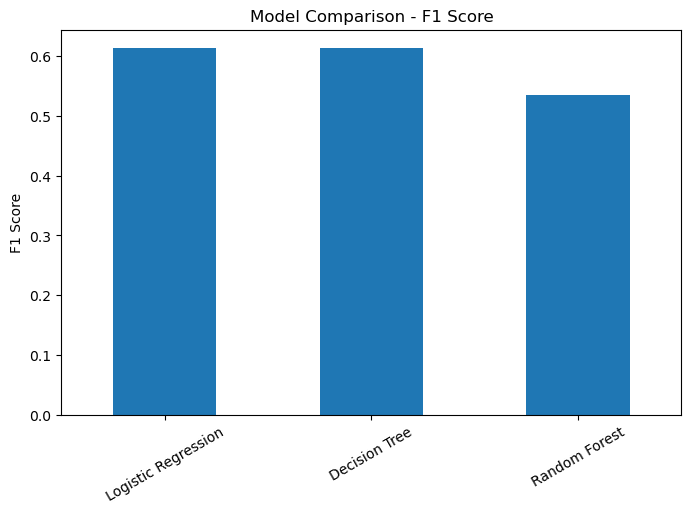

In [36]:
model_results["F1"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Comparison - F1 Score")
plt.ylabel("F1 Score")
plt.xticks(rotation=30)
plt.show()

In [39]:
final_model = logistic_model

In [40]:
final_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
y_test_pred = final_model.predict(
    X_test
)

y_test_prob = final_model.predict_proba(
    X_test
)[:, 1]

In [42]:
test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_precision = precision_score(
    y_test,
    y_test_pred
)

test_recall = recall_score(
    y_test,
    y_test_pred
)

test_f1 = f1_score(
    y_test,
    y_test_pred
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_prob
)

In [43]:
print("Accuracy :", test_accuracy)
print("Precision:", test_precision)
print("Recall   :", test_recall)
print("F1 Score :", test_f1)
print("ROC-AUC  :", test_roc_auc)

Accuracy : 0.7947019867549668
Precision: 0.66
Recall   : 0.4697508896797153
F1 Score : 0.5488565488565489
ROC-AUC  : 0.8426275819055655


In [44]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "No Churn",
            "Churn"
        ]
    )
)

              precision    recall  f1-score   support

    No Churn       0.83      0.91      0.87       776
       Churn       0.66      0.47      0.55       281

    accuracy                           0.79      1057
   macro avg       0.74      0.69      0.71      1057
weighted avg       0.78      0.79      0.78      1057



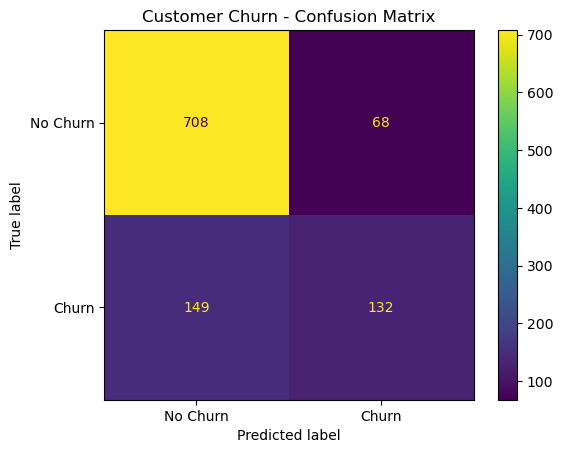

In [45]:
cm = confusion_matrix(
    y_test,
    y_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Churn",
        "Churn"
    ]
)

disp.plot()

plt.title("Customer Churn - Confusion Matrix")
plt.show()

In [46]:
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test.values

error_analysis["Predicted"] = y_test_pred

In [47]:
errors = error_analysis[
    error_analysis["Actual"] !=
    error_analysis["Predicted"]
]

errors.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TenureGroup,Actual,Predicted
1639,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Electronic check,45.05,770.60,1-2 Years,1,0
517,Female,1,Yes,No,5,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,No,Electronic check,70.05,302.60,0-1 Year,0,1
6137,Female,0,No,No,5,Yes,No,DSL,Yes,No,...,No,No,Month-to-month,No,Credit card (automatic),53.85,259.80,0-1 Year,1,0
3251,Female,1,No,No,37,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),106.75,4056.75,2-4 Years,1,0
3362,Female,0,No,No,1,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Electronic check,54.90,54.90,0-1 Year,1,0


In [48]:
false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
]

print(
    "False Positives:",
    len(false_positives)
)

False Positives: 68


In [49]:
false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
]

print(
    "False Negatives:",
    len(false_negatives)
)

False Negatives: 149


In [50]:
joblib.dump(
    final_model,
    "../models/customer_churn_model.pkl"
)

['../models/customer_churn_model.pkl']

In [51]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],

    "Value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_roc_auc
    ]
})

final_results.to_csv(
    "../results/final_test_results.csv",
    index=False
)